<a href="https://colab.research.google.com/github/antonio-velazquezr/PredictiveProcessing-LFP/blob/main/lfp_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LFP analysis in 9 small steps

Welcome! This notebook walks through the basic tools for analysing local field potentials
(LFP), using real Neuropixels data from the OpenScope Predictive Processing project
([DANDI 001637](https://dandiarchive.org/dandiset/001637)). We use **one mouse** and **one
channel in V1**, so everything runs in a few minutes on Colab.

**How to use it:** run the cells from top to bottom (Shift + Enter). Values in `CAPITALS`
at the top of a cell are meant to be changed: try other numbers and run the cell again.
Nothing can break: if something goes wrong, just re-run from the top.

| Step | What you learn |
|---|---|
| 1 | Get the data straight from the archive |
| 2 | Look at the raw LFP |
| 3 | Digital filters |
| 4 | Power spectrum (PSD) |
| 5 | Tapering |
| 6 | PSD with tapering: standard vs oddball |
| 7 | Band-pass filter + Hilbert transform |
| 8 | Wavelet transform |
| 9 | Spike–field coherence |

**The experiment in one sentence:** the mouse sees the same drifting grating over and over
(the *standard*), and once in a while something unexpected happens (an *oddball*: a new
orientation, the grating stops, or it is skipped).

## 1 · Get the data

The data live in an NWB file on DANDI. We **stream** it: only the pieces we look at are
downloaded, so there is nothing to store.

In [ ]:
!pip -q install dandi remfile pynwb h5py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [ ]:
SESSION = "sub-820454/sub-820454_ses-ecephys-820454-2025-11-05-15-21-15_ecephys.nwb"
AREA = "VISp2/3"          # V1, layer 2/3. Try "VISp4", "VISp5" or "LGd" (thalamus)

import h5py, remfile
from dandi.dandiapi import DandiAPIClient
from pynwb import NWBHDF5IO

with DandiAPIClient() as client:
    asset = client.get_dandiset("001637", "draft").get_asset_by_path(SESSION)
    url = asset.get_content_url(follow_redirects=True, strip_query=True)
io = NWBHDF5IO(file=h5py.File(remfile.File(url), "r"), mode="r")
nwb = io.read()

# Every LFP channel and the brain region it sits in
electrodes = nwb.electrodes.to_dataframe().reset_index()
probes = nwb.processing["ecephys"]["LFP"].electrical_series
channels = pd.DataFrame([
    {"probe": name, "column": col, "row": int(row), "location": electrodes["location"].iloc[int(row)]}
    for name, es in probes.items() for col, row in enumerate(es.electrodes.data[:])])

ch = channels[channels["location"] == AREA].iloc[0]        # our channel
es = probes[ch["probe"]]
if es.timestamps is not None:                               # time of each sample (s)
    ts = np.asarray(es.timestamps[:])
else:
    ts = es.starting_time + np.arange(es.data.shape[0]) / es.rate
FS = 1 / np.median(np.diff(ts[:1000]))                      # samples per second


def get_lfp(t0, t1, column=int(ch["column"])):
    # Time (s) and LFP (microvolts) between t0 and t1 seconds.
    i0, i1 = np.searchsorted(ts, [t0, t1])
    return ts[i0:i1], es.data[i0:i1, column] * es.conversion * 1e6


print(f"Channel {ch['column']} of {ch['probe']} in {AREA}; sampling rate {FS:.0f} Hz")

ERROR:dandi:Error 403 while sending HEAD request to https://api.dandiarchive.org/api/assets/21988ae7-fce0-41f2-a2af-b6c2ddcd6e52/download/: 
/usr/local/lib/python3.13/dist-packages/hdmf/common/table.py:559: UserWarning: An attribute 'name' already exists on TimeIntervals '40 hz pulse train_presentations' so this column cannot be accessed as an attribute, e.g., table.name; it can only be accessed using other methods, e.g., table['name'].
  self.__set_table_attr(col)
/usr/local/lib/python3.13/dist-packages/hdmf/common/table.py:559: UserWarning: An attribute 'name' already exists on TimeIntervals '5 hz pulse train_presentations' so this column cannot be accessed as an attribute, e.g., table.name; it can only be accessed using other methods, e.g., table['name'].
  self.__set_table_attr(col)
/usr/local/lib/python3.13/dist-packages/hdmf/common/table.py:559: UserWarning: An attribute 'name' already exists on TimeIntervals 'raised_cosine_presentations' so this column cannot be accessed as an a

Channel 68 of ElectricalSeriesProbeC-LFP in VISp2/3; sampling rate 1250 Hz


In [ ]:
stim = nwb.intervals["Standard mismatch block_presentations"].to_dataframe()
stim = stim.rename(columns={c: "type" for c in stim.columns if c.lower() in ("trialtype", "trial_type")})
print(stim["type"].value_counts())

COLORS = {"standard": "grey", "orientation_45": "red", "orientation_90": "orange",
          "halt": "green", "omission": "purple"}
STIM_DUR = (stim["stop_time"] - stim["start_time"]).median()   # seconds a grating is on


def shade_stimuli(ax, t0, t1, zero=0.0):
    # Colour the time each stimulus was on screen.
    on = stim[(stim["stop_time"] > t0) & (stim["start_time"] < t1)]
    for _, s in on.iterrows():
        ax.axvspan(s["start_time"] - zero, s["stop_time"] - zero, color=COLORS[s["type"]],
                   alpha=0.15, lw=0)

type
standard          2134
omission            35
orientation_90      35
halt                35
orientation_45      35
Name: count, dtype: int64


## 2 · Look at the raw LFP

The LFP is the slow part of the extracellular voltage: the summed synaptic currents of many
neurons near the electrode. Coloured bands show when each stimulus was on (grey = standard,
red = 45° oddball).

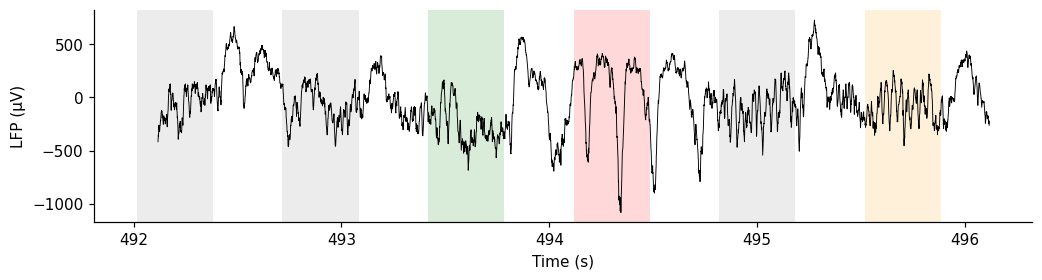

In [ ]:
first_oddball = stim.loc[stim["type"] == "orientation_45", "start_time"].iloc[0]
T_START = first_oddball - 2     # seconds; try any time in the session
DURATION = 4

t, lfp = get_lfp(T_START, T_START + DURATION)
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.plot(t, lfp, color="k", lw=0.6)
shade_stimuli(ax, t[0], t[-1])
ax.set_xlabel("Time (s)"); ax.set_ylabel("LFP (µV)")
plt.show()

Now several channels along the same probe, from deep (bottom) to superficial (top).
Neighbouring channels look alike because they pick up many of the same sources.

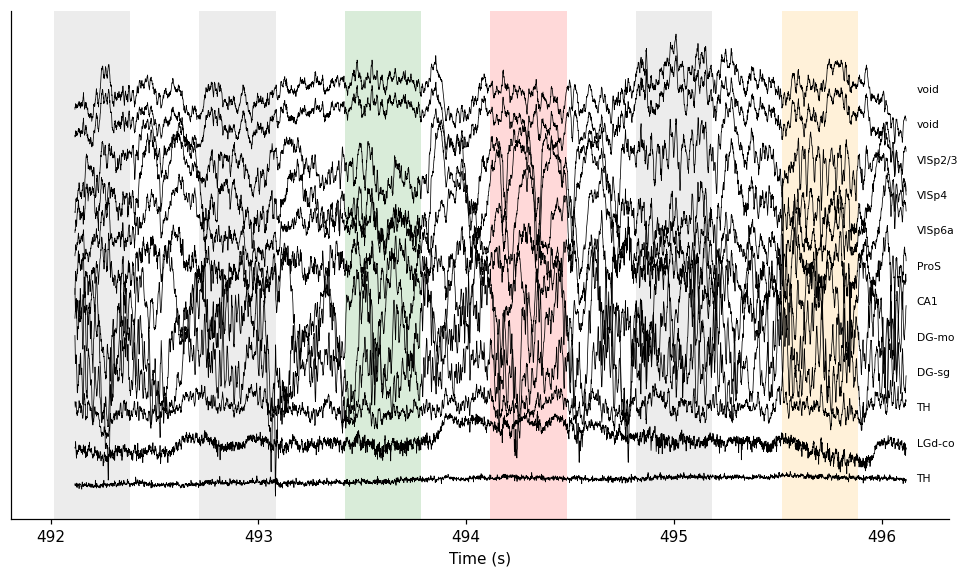

In [ ]:
EVERY_NTH = 8                   # plot one channel out of every N
SPACING = 300                   # µV between traces

probe = channels[channels["probe"] == ch["probe"]].iloc[::EVERY_NTH]
fig, ax = plt.subplots(figsize=(11, 6))
for k, (_, c) in enumerate(probe.iterrows()):
    t, x = get_lfp(T_START, T_START + DURATION, column=int(c["column"]))
    ax.plot(t, x + k * SPACING, color="k", lw=0.5)
    ax.text(t[-1] + 0.05, k * SPACING, c["location"], fontsize=7, va="center")
shade_stimuli(ax, t[0], t[-1])
ax.set_yticks([]); ax.set_xlabel("Time (s)")
plt.show()

## 3 · Digital filters

A filter keeps some frequencies and removes others:

* **low-pass**: keeps slow activity (here below 100 Hz)
* **high-pass**: keeps fast activity
* **band-pass**: keeps one band (here 20–35 Hz)

We use **Butterworth** filters and apply them with `sosfiltfilt`, which runs the filter
forwards and then backwards. That way the filtered signal is **not shifted in time**.

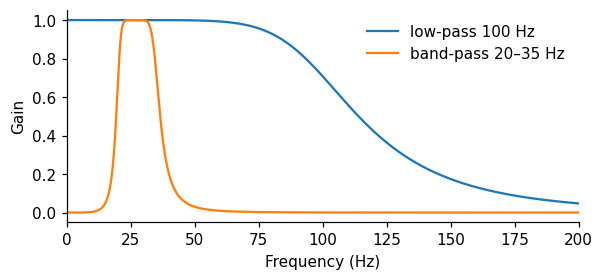

In [ ]:
LOW_PASS = 100                  # Hz
BAND = (20, 35)                 # Hz

lowpass = signal.butter(4, LOW_PASS, btype="lowpass", fs=FS, output="sos")
bandpass = signal.butter(4, BAND, btype="bandpass", fs=FS, output="sos")

# What each filter lets through (1 = everything, 0 = nothing)
fig, ax = plt.subplots(figsize=(6, 2.5))
for sos, name in ((lowpass, f"low-pass {LOW_PASS} Hz"), (bandpass, f"band-pass {BAND[0]}–{BAND[1]} Hz")):
    f, h = signal.sosfreqz(sos, worN=4096, fs=FS)
    ax.plot(f, np.abs(h), label=name)
ax.set_xlim(0, 200); ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Gain"); ax.legend(frameon=False)
plt.show()

In [ ]:
t, lfp = get_lfp(T_START, T_START + DURATION)

fig, axs = plt.subplots(3, 1, figsize=(11, 5), sharex=True)
axs[0].plot(t, lfp, color="grey", lw=0.5); axs[0].set_title("raw", fontsize=9)
axs[1].plot(t, signal.sosfiltfilt(lowpass, lfp), color="k", lw=0.6)
axs[1].set_title(f"low-pass {LOW_PASS} Hz", fontsize=9)
axs[2].plot(t, signal.sosfiltfilt(bandpass, lfp), color="tab:blue", lw=0.6)
axs[2].set_title(f"band-pass {BAND[0]}–{BAND[1]} Hz", fontsize=9)
for ax in axs:
    shade_stimuli(ax, t[0], t[-1]); ax.set_ylabel("µV")
axs[2].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

## 4 · Power spectrum (PSD)

The Fourier transform splits a signal into sine waves. The **power spectral density** says
how much power each frequency has. LFP spectra fall steeply with frequency ("1/f"), so we
plot them on log axes.

A single spectrum is very noisy. **Welch's method** cuts the signal into short pieces
(here 1 s), computes a spectrum for each, and averages them.

In [ ]:
SECONDS = 60                    # how much data to use

t, lfp = get_lfp(T_START, T_START + SECONDS)
freqs, psd = signal.welch(lfp, fs=FS, window="boxcar", nperseg=int(FS))   # boxcar = no taper yet

fig, ax = plt.subplots(figsize=(5, 3))
ax.loglog(freqs[1:], psd[1:], color="k")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Power (µV²/Hz)")
plt.show()

## 5 · Tapering

Cutting a piece out of a signal with sharp edges creates fake power at frequencies that are
not really there (**spectral leakage**). Multiplying the piece by a smooth window that goes
to zero at the edges (a **taper**) fixes most of it.

Below: a pure 30 Hz sine. Without a taper (grey) the power leaks everywhere; with a taper it
stays at 30 Hz.

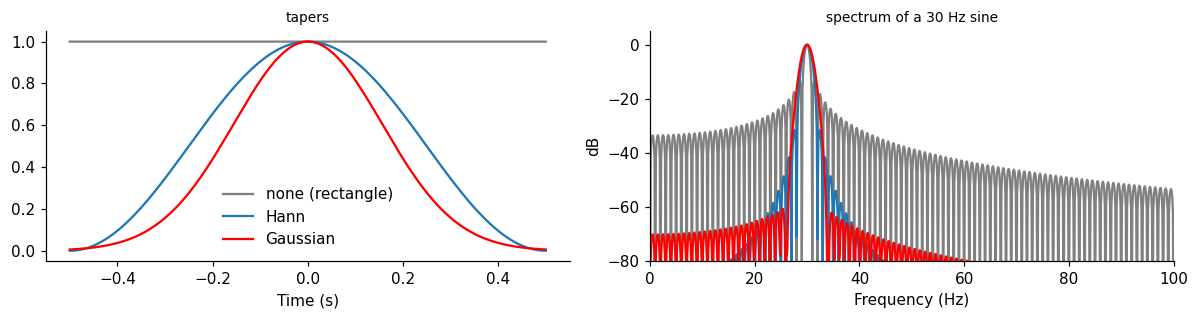

In [ ]:
n = int(FS)                                   # a 1 s piece
time = np.arange(n) / FS - 0.5                # centred on 0
sine = np.sin(2 * np.pi * 30 * time)

sigma = STIM_DUR / 2.355                      # Gaussian as wide as one stimulus (FWHM)
tapers = {"none (rectangle)": np.ones(n),
          "Hann": signal.windows.hann(n),
          "Gaussian": np.exp(-0.5 * (time / sigma) ** 2)}

fig, axs = plt.subplots(1, 2, figsize=(11, 3))
for (name, w), color in zip(tapers.items(), ["grey", "tab:blue", "red"]):
    axs[0].plot(time, w, color=color, label=name)
    f, p = signal.periodogram(sine * w, fs=FS, nfft=8 * n)
    axs[1].plot(f, 10 * np.log10(p / p.max() + 1e-12), color=color)
axs[0].set_xlabel("Time (s)"); axs[0].set_title("tapers", fontsize=9); axs[0].legend(frameon=False)
axs[1].set_xlim(0, 100); axs[1].set_ylim(-80, 5)
axs[1].set_xlabel("Frequency (Hz)"); axs[1].set_ylabel("dB")
axs[1].set_title("spectrum of a 30 Hz sine", fontsize=9)
plt.tight_layout(); plt.show()

## 6 · PSD with tapering: standard vs oddball

Now a real question: is the LFP spectrum different when the mouse sees an oddball?

For every trial we take 1 s of LFP centred on the stimulus and multiply it by the Gaussian
taper. Its width equals the stimulus duration, so it also **focuses on the stimulus** and
down-weights the neighbouring ones. Then we average the spectra over trials.

In [ ]:
N_TRIALS = 40
CONDITIONS = ["standard", "orientation_45"]        # try "orientation_90", "halt", "omission"

gaussian = tapers["Gaussian"]
centres = (stim["start_time"] + stim["stop_time"]) / 2
spectra = {}
for cond in CONDITIONS:
    trials = []
    for c in centres[stim["type"] == cond][:N_TRIALS]:
        t, x = get_lfp(c - 0.5, c + 0.5)
        x = x[:n] - x[:n].mean()
        f, p = signal.periodogram(x * gaussian, fs=FS, nfft=4 * n)
        trials.append(p)
    spectra[cond] = 10 * np.log10(np.array(trials)[:, f > 0])   # decibels (skip 0 Hz)
f = f[f > 0]

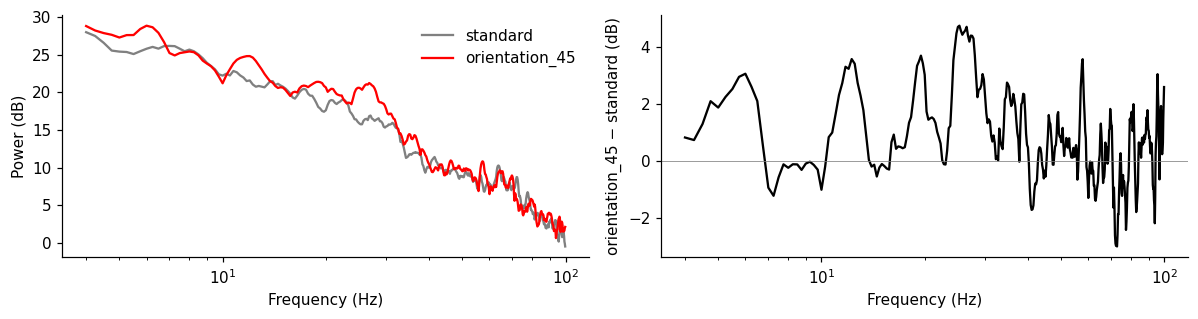

In [ ]:
keep = (f >= 4) & (f <= 100)
fig, axs = plt.subplots(1, 2, figsize=(11, 3))
for cond, db in spectra.items():
    axs[0].plot(f[keep], db[:, keep].mean(0), color=COLORS[cond], label=cond)
axs[0].set_xscale("log"); axs[0].set_ylabel("Power (dB)"); axs[0].legend(frameon=False)

difference = spectra[CONDITIONS[1]].mean(0) - spectra[CONDITIONS[0]].mean(0)
axs[1].plot(f[keep], difference[keep], color="k"); axs[1].axhline(0, color="grey", lw=0.5)
axs[1].set_xscale("log"); axs[1].set_ylabel(f"{CONDITIONS[1]} − {CONDITIONS[0]} (dB)")
for ax in axs:
    ax.set_xlabel("Frequency (Hz)")
plt.tight_layout(); plt.show()

*Careful:* the oddball is also a different orientation from the standard, and the standard
has been repeated many times (adaptation). To know whether a difference is about *surprise*,
compare with the same grating shown in the control block.

## 7 · Band-pass filter + Hilbert transform

To follow **one rhythm** over time: band-pass it (step 3), then apply the **Hilbert
transform**. This gives, at every sample,

* the **amplitude envelope**: how strong the rhythm is, and
* the **phase**: where we are in the cycle (0 = peak, ±π = trough).

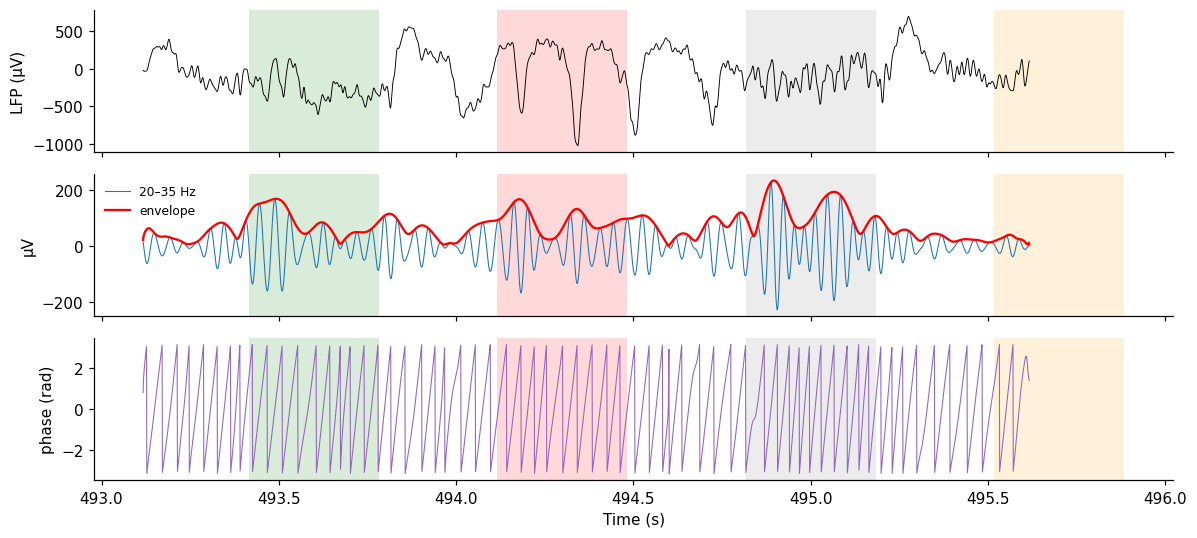

In [ ]:
oddball = stim[stim["type"] == "orientation_45"].iloc[0]
t, x = get_lfp(oddball["start_time"] - 1, oddball["start_time"] + 1.5)

band = signal.sosfiltfilt(bandpass, x)
analytic = signal.hilbert(band)
envelope, phase = np.abs(analytic), np.angle(analytic)

fig, axs = plt.subplots(3, 1, figsize=(11, 5), sharex=True)
axs[0].plot(t, signal.sosfiltfilt(lowpass, x), color="k", lw=0.6); axs[0].set_ylabel("LFP (µV)")
axs[1].plot(t, band, color="tab:blue", lw=0.7, label=f"{BAND[0]}–{BAND[1]} Hz")
axs[1].plot(t, envelope, color="red", label="envelope"); axs[1].set_ylabel("µV")
axs[1].legend(frameon=False, fontsize=8)
axs[2].plot(t, phase, color="tab:purple", lw=0.7); axs[2].set_ylabel("phase (rad)")
axs[2].set_xlabel("Time (s)")
for ax in axs:
    shade_stimuli(ax, t[0], t[-1])
plt.tight_layout(); plt.show()

## 8 · Wavelet transform

The PSD tells you *which* frequencies, but not *when*. A **Morlet wavelet** is a short sine
wave inside a Gaussian. Sliding it along the signal measures each frequency at each moment.

With the same number of cycles at every frequency, the wavelet is long at low frequencies
(precise in frequency, blurry in time) and short at high frequencies (the opposite).

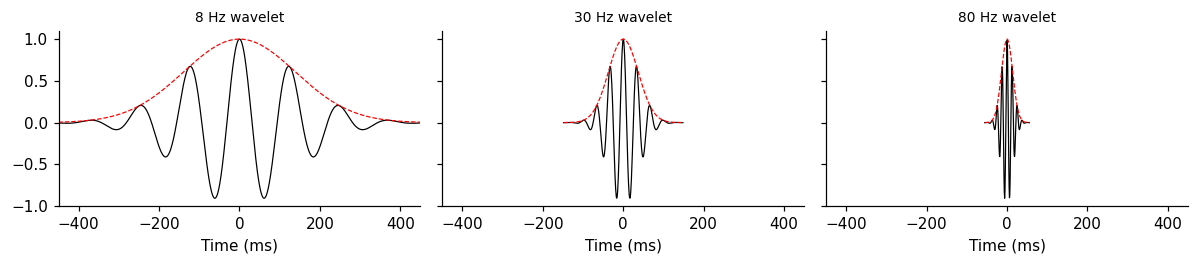

In [ ]:
N_CYCLES = 7


def morlet(freq, n_cycles=N_CYCLES):
    sd = n_cycles / (2 * np.pi * freq)                # width of the Gaussian (s)
    t = np.arange(-4 * sd, 4 * sd, 1 / FS)
    return t, np.exp(2j * np.pi * freq * t) * np.exp(-0.5 * (t / sd) ** 2)


fig, axs = plt.subplots(1, 3, figsize=(11, 2.5), sharey=True)
for ax, freq in zip(axs, [8, 30, 80]):
    t, w = morlet(freq)
    ax.plot(t * 1000, w.real, color="k", lw=0.8)
    ax.plot(t * 1000, np.abs(w), "r--", lw=0.8)
    ax.set_title(f"{freq} Hz wavelet", fontsize=9); ax.set_xlabel("Time (ms)"); ax.set_xlim(-450, 450)
plt.tight_layout(); plt.show()

In [ ]:
FREQS = np.geomspace(4, 100, 40)          # 40 frequencies, log-spaced
BEFORE, AFTER = 0.3, 0.8                  # seconds around stimulus onset


def wavelet_power(x):
    # Power (frequencies x time) of signal x.
    out = []
    for freq in FREQS:
        _, w = morlet(freq)
        w = w / np.abs(w).sum()
        out.append(np.abs(signal.fftconvolve(x, w, mode="same")) ** 2)
    return np.array(out)


power = {}
for cond in CONDITIONS:
    trials = []
    for onset in stim.loc[stim["type"] == cond, "start_time"][:N_TRIALS]:
        t, x = get_lfp(onset - BEFORE - 0.6, onset + AFTER + 0.6)    # 0.6 s extra each side...
        p = wavelet_power(x)
        keep = (t >= onset - BEFORE) & (t < onset + AFTER)           # ...cut away here (edges)
        trials.append(p[:, keep][:, : int((BEFORE + AFTER) * FS)])
    power[cond] = np.mean(trials, axis=0)

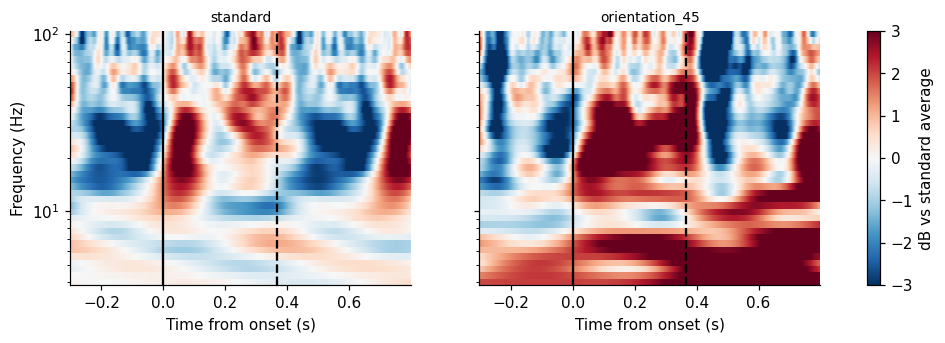

In [ ]:
time = np.arange(power[CONDITIONS[0]].shape[1]) / FS - BEFORE
reference = power["standard"].mean(axis=1, keepdims=True)           # standard's average power

fig, axs = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, cond in zip(axs, CONDITIONS):
    db = 10 * np.log10(power[cond] / reference)
    im = ax.pcolormesh(time, FREQS, db, cmap="RdBu_r", vmin=-3, vmax=3)
    ax.axvline(0, color="k"); ax.axvline(STIM_DUR, color="k", ls="--")
    ax.set_yscale("log"); ax.set_title(cond, fontsize=9); ax.set_xlabel("Time from onset (s)")
axs[0].set_ylabel("Frequency (Hz)")
fig.colorbar(im, ax=axs, label="dB vs standard average")
plt.show()

Stimuli come every ~0.7 s, so there is no quiet "baseline" before each one. That is why both
maps are shown relative to the standard's average power.

## 9 · Spike–field coherence

Do individual neurons fire in time with the LFP rhythm? For every spike of a neuron we read
the **phase** of the 20–35 Hz rhythm (step 7) at that moment.

* A **phase-locked** neuron prefers one phase: its phase histogram is lopsided.
* A neuron that ignores the rhythm gives a flat histogram.

We summarise this with the **pairwise phase consistency (PPC)**: 0 = no locking, larger =
stronger locking. Unlike simpler measures, it is not biased by how many spikes a neuron
fires (Vinck et al., 2010).

One rule: never measure a neuron against the LFP of the **same channel** that recorded it.
Its own spikes leak into the filtered LFP and fake the locking.

In [ ]:
MAX_NEURONS = 60

# Where each neuron is: the electrode with its biggest spike (its "peak channel")
units = nwb.units
regions = units["electrodes"]
rows, ends = np.asarray(regions.target.data[:]), np.asarray(regions.data[:])
starts = np.r_[0, ends[:-1]]
extremum = np.asarray(units["extremum_channel_index"].data[:])
peak = np.array([rows[s:e][i] for s, e, i in zip(starts, ends, extremum)])
location = electrodes["location"].to_numpy()[peak]

v1 = pd.Series(location).str.match(r"VISp\d").to_numpy()        # V1, any layer
good = np.asarray(units["default_qc"].data[:]).astype(str) == "True"    # spike-sorting quality
not_our_channel = peak != ch["row"]
neurons = np.flatnonzero(v1 & good & not_our_channel)[:MAX_NEURONS]

spike_times = {u: np.asarray(units["spike_times"][u]) for u in neurons}
print(f"{len(neurons)} V1 neurons loaded")

60 V1 neurons loaded


In [ ]:
SECONDS = 300                                      # LFP used to measure the phase

t0 = stim["start_time"].min()
t, x = get_lfp(t0, t0 + SECONDS)
band = signal.sosfiltfilt(bandpass, x)
phase = np.angle(signal.hilbert(band))


def ppc(phases):
    n = len(phases)
    R = np.abs(np.mean(np.exp(1j * phases)))
    return (n * R ** 2 - 1) / (n - 1)


results = []
for u, spikes in spike_times.items():
    spikes = spikes[(spikes > t[0] + 1) & (spikes < t[-1] - 1)]
    if len(spikes) >= 100:
        spike_phase = phase[np.searchsorted(t, spikes)]
        results.append({"neuron": u, "location": location[u], "spikes": len(spikes),
                        "ppc": ppc(spike_phase), "phases": spike_phase, "times": spikes})
results = pd.DataFrame(results).sort_values("ppc", ascending=False)
print(results[["neuron", "location", "spikes", "ppc"]].round(4).head(10).to_string(index=False))

 neuron location  spikes    ppc
   1800    VISp5     408 0.2026
   1827    VISp5    5317 0.1306
   1775   VISp6a    9850 0.1181
   1819    VISp5    3012 0.1002
   1795    VISp5    2161 0.0620
   1773   VISp6a     747 0.0563
   1832    VISp5    4265 0.0480
   1776    VISp5     198 0.0379
   1791    VISp5     789 0.0368
   1815    VISp5    7647 0.0358


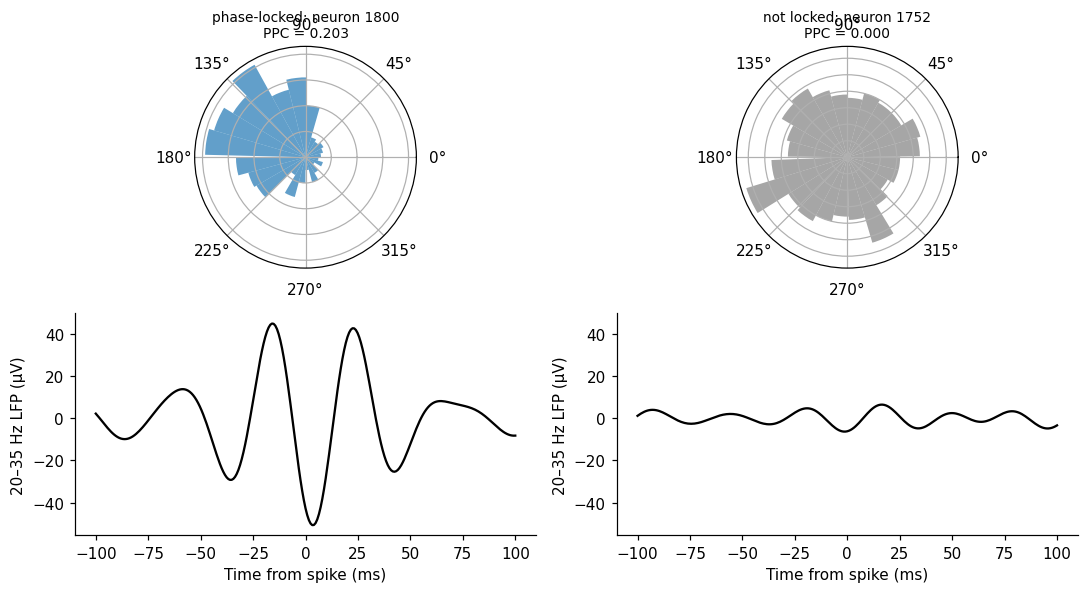

In [ ]:
locked = results.iloc[0]                                          # strongest locking
not_locked = results.iloc[np.argmin(np.abs(results["ppc"]))]      # PPC closest to 0
half = int(0.1 * FS)                                              # ±100 ms around each spike

fig = plt.figure(figsize=(10, 5.5))
for j, (title, neuron) in enumerate([("phase-locked", locked), ("not locked", not_locked)]):
    ax = fig.add_subplot(2, 2, j + 1, projection="polar")
    ax.hist(neuron["phases"], bins=24, color="tab:blue" if j == 0 else "grey", alpha=0.7)
    ax.set_yticklabels([])
    ax.set_title(f"{title}: neuron {neuron['neuron']}\nPPC = {neuron['ppc']:.3f}", fontsize=9)

    ax = fig.add_subplot(2, 2, j + 3, sharey=fig.axes[1] if j else None)
    idx = np.searchsorted(t, neuron["times"])
    idx = idx[(idx > half) & (idx < len(t) - half)]
    average = np.mean([band[i - half:i + half + 1] for i in idx], axis=0)
    ax.plot(np.arange(-half, half + 1) / FS * 1000, average, color="k")
    ax.set_xlabel("Time from spike (ms)"); ax.set_ylabel(f"{BAND[0]}–{BAND[1]} Hz LFP (µV)")
plt.tight_layout(); plt.show()

The bottom row is the **spike-triggered average**: the band-passed LFP averaged around every
spike. A locked neuron shows a clear oscillation around its spikes; a non-locked one shows
almost nothing.

### Ideas to try next

* Change `AREA` in step 1 (e.g. `"VISp5"`, `"LGd"`) and re-run everything.
* Compare other oddballs in `CONDITIONS` (`"orientation_90"`, `"halt"`, `"omission"`).
* Change `BAND` in step 3 and see how the Hilbert and coherence results change.
* Measure spike–field coherence separately for spikes during standards and during oddballs.